## Описание столбцов датасета (Cirrhosis Patient Survival Prediction)

В наборе данных 20 столбцов: идентификатор, длительность наблюдения, целевая переменная и 17 клинических признаков.

### Идентификатор и целевые показатели
* **`ID`** — уникальный порядковый номер пациента в исследовании.
* **`N_Days`** — количество дней от момента регистрации пациента до самого раннего из трёх событий: смерти, трансплантации печени или окончания анализа (июль 1986 года).
* **`Status`** — итоговый статус пациента (целевая переменная):
  * `C` *(censored)* — пациент был жив на момент окончания наблюдения;
  * `CL` *(censored due to liver tx)* — жив благодаря трансплантации печени;
  * `D` *(death)* — летальный исход.

### Демография и лечение
* **`Drug`** — назначенный препарат в рамках исследования: `D-penicillamine` (Д-пеницилламин) или `Placebo` (плацебо).
* **`Age`** — возраст пациента в **днях**.
* **`Sex`** — пол пациента: `M` (мужской) или `F` (женский).

### Клинические симптомы (осмотр врача)
* **`Ascites`** — наличие асцита (скопления свободной жидкости в брюшной полости): `N` (нет) или `Y` (да).
* **`Hepatomegaly`** — наличие гепатомегалии (патологического увеличения печени): `N` (нет) или `Y` (да).
* **`Spiders`** — наличие сосудистых «звёздочек» (телеангиэктазий) на коже: `N` (нет) или `Y` (да).
* **`Edema`** — наличие периферических отёков:
  * `N` — отёков нет, диуретики не принимаются;
  * `S` — отёки есть без диуретиков или сняты ими;
  * `Y` — отёки сохраняются даже на фоне приёма диуретиков.

### Лабораторные анализы крови и тяжесть болезни
* **`Bilirubin`** — уровень сывороточного билирубина (мг/дл), показатель желтухи и способности печени выводить желчь.
* **`Cholesterol`** — уровень холестерина в сыворотке крови (мг/дл).
* **`Albumin`** — уровень альбумина в сыворотке крови (г/дл), важный белок, синтезируемый печенью.
* **`Copper`** — уровень меди в суточной моче (мкг/день).
* **`Alk_Phos`** — уровень щелочной фосфатазы (Ед/л), фермента, указывающего на застой желчи.
* **`SGOT`** — уровень фермента АСТ / глутамат-оксалоацетат-трансаминазы (Ед/мл), отражает повреждение клеток печени.
* **`Triglycerides`** — уровень триглицеридов (жиров) в крови (мг/дл).
* **`Platelets`** — количество тромбоцитов в крови (тыс./мм³).
* **`Prothrombin`** — протромбиновое время (в секундах), показатель свёртываемости крови.
* **`Stage`** — гистологическая стадия цирроза печени по результатам биопсии (от `1` до `4`, где `4` — наиболее тяжёлая стадия).


# EDA: Cirrhosis Patient Survival Prediction

## 1. Загрузка и первичный осмотр

### 1.1 Импорт библиотек

In [111]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from math import pi

from scipy.stats import chi2_contingency


### 1.2 Загрузка данных

In [112]:
df_train = pd.read_csv("../data/train.csv")

### 1.3 Первый взгляд

In [113]:
df_train.head()

,id,N_Days,Drug,Age,Sex,Ascites,Hepatomegaly,Spiders,Edema,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage,Status
0,0,999,D-penicillamine,21532,M,N,N,N,N,2.3,316.0,3.35,172.0,1601.0,179.80,63.0,394.0,9.7,3.0,D
1,1,2574,Placebo,19237,F,N,N,N,N,0.9,364.0,3.54,63.0,1440.0,134.85,88.0,361.0,11.0,3.0,C
2,2,3428,Placebo,13727,F,N,Y,Y,Y,3.3,299.0,3.55,131.0,1029.0,119.35,50.0,199.0,11.7,4.0,D
3,3,2576,Placebo,18460,F,N,N,N,N,0.6,256.0,3.50,58.0,1653.0,71.30,96.0,269.0,10.7,3.0,C
4,4,788,Placebo,16658,F,N,Y,N,N,1.1,346.0,3.65,63.0,1181.0,125.55,96.0,298.0,10.6,4.0,C


In [114]:
df_train.sample(5, random_state=42)

,id,N_Days,Drug,Age,Sex,Ascites,Hepatomegaly,Spiders,Edema,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage,Status
3467,3467,971,D-penicillamine,20555,F,N,N,N,N,0.8,328.0,3.50,65.0,688.0,60.45,213.0,265.0,9.8,3.0,C
465,465,1810,D-penicillamine,20555,F,N,Y,Y,N,3.3,361.0,3.57,34.0,12258.8,72.85,104.0,341.0,10.6,4.0,C
453,453,2176,Placebo,17263,M,N,N,N,N,1.2,232.0,3.98,11.0,1074.0,100.75,99.0,223.0,9.9,3.0,C
4913,4913,1462,Placebo,23331,F,N,N,N,N,0.4,258.0,3.74,49.0,559.0,43.40,177.0,284.0,10.5,3.0,D
5907,5907,1216,Placebo,19994,F,N,Y,N,N,0.7,336.0,3.36,44.0,1826.0,97.65,110.0,256.0,9.5,1.0,C


### 1.4 Структура и размер данных

In [115]:
df_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 7905 entries, 0 to 7904
Data columns (total 20 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             7905 non-null   int64  
 1   N_Days         7905 non-null   int64  
 2   Drug           7905 non-null   str    
 3   Age            7905 non-null   int64  
 4   Sex            7905 non-null   str    
 5   Ascites        7905 non-null   str    
 6   Hepatomegaly   7905 non-null   str    
 7   Spiders        7905 non-null   str    
 8   Edema          7905 non-null   str    
 9   Bilirubin      7905 non-null   float64
 10  Cholesterol    7905 non-null   float64
 11  Albumin        7905 non-null   float64
 12  Copper         7905 non-null   float64
 13  Alk_Phos       7905 non-null   float64
 14  SGOT           7905 non-null   float64
 15  Tryglicerides  7905 non-null   float64
 16  Platelets      7905 non-null   float64
 17  Prothrombin    7905 non-null   float64
 18  Stage          7905

In [116]:
memory_before = df_train.memory_usage(deep=True).sum() / 1024**2
print(f"💾 Память до: {memory_before:.2f} MB")

💾 Память до: 3.50 MB


### 1.5 Пропуски и дубликаты

In [117]:
# точные дубликаты по всем признакам (без id)
print("Дубликатов без id:", df_train.drop(columns='id').duplicated().sum())

# сколько уникальных комбинаций признаков
print("Уникальных строк (без id):", df_train.drop(columns='id').drop_duplicates().shape[0])

Дубликатов без id: 0
Уникальных строк (без id): 7905


## 2. Первичная статистика

### 2.1 Категориальные признаки: уникальные значения и частоты

In [118]:
cat_cols = ['Drug','Sex','Ascites','Hepatomegaly','Spiders','Edema','Status']

for c in cat_cols:
    print(f"Признак {c}: {df_train[c].nunique()} уникальных значений")
    print(df_train[c].value_counts())
    print()

Признак Drug: 2 уникальных значений
Drug
Placebo            4010
D-penicillamine    3895
Name: count, dtype: int64

Признак Sex: 2 уникальных значений
Sex
F    7336
M     569
Name: count, dtype: int64

Признак Ascites: 2 уникальных значений
Ascites
N    7525
Y     380
Name: count, dtype: int64

Признак Hepatomegaly: 2 уникальных значений
Hepatomegaly
Y    4042
N    3863
Name: count, dtype: int64

Признак Spiders: 2 уникальных значений
Spiders
N    5966
Y    1939
Name: count, dtype: int64

Признак Edema: 3 уникальных значений
Edema
N    7161
S     399
Y     345
Name: count, dtype: int64

Признак Status: 3 уникальных значений
Status
C     4965
D     2665
CL     275
Name: count, dtype: int64



### 2.2 Числовые признаки

In [119]:
df_train.describe().T

,count,mean,std,min,25%,50%,75%,max
id,7905.0,3952.000000,2282.121272,0.00,1976.00,3952.00,5928.00,7904.00
N_Days,7905.0,2030.173308,1094.233744,41.00,1230.00,1831.00,2689.00,4795.00
Age,7905.0,18373.146490,3679.958739,9598.00,15574.00,18713.00,20684.00,28650.00
Bilirubin,7905.0,2.594485,3.812960,0.30,0.70,1.10,3.00,28.00
Cholesterol,7905.0,350.561923,195.379344,120.00,248.00,298.00,390.00,1775.00
Albumin,7905.0,3.548323,0.346171,1.96,3.35,3.58,3.77,4.64
Copper,7905.0,83.902846,75.899266,4.00,39.00,63.00,102.00,588.00
Alk_Phos,7905.0,1816.745250,1903.750657,289.00,834.00,1181.00,1857.00,13862.40
SGOT,7905.0,114.604602,48.790945,26.35,75.95,108.50,137.95,457.25
Tryglicerides,7905.0,115.340164,52.530402,33.00,84.00,104.00,139.00,598.00


### 2.3 Асимметрия и форма распределений

Проверяем коэффициент асимметрии (skew) для числовых признаков.
Признаки с `|skew| > 1` — кандидаты на логарифмирование (`np.log1p`),
так как сильно смещены вправо.

In [120]:
num_cols = df_train.select_dtypes('number').drop(columns='id').columns.tolist()

skew_table = (df_train[num_cols].skew()
              .sort_values(ascending=False)
              .to_frame(name='skew'))

skew_table['abs_skew'] = skew_table['skew'].abs()
skew_table['needs_log'] = skew_table['abs_skew'] > 1

skew_table.round(3)

,skew,abs_skew,needs_log
Cholesterol,3.680,3.680,True
Bilirubin,3.340,3.340,True
Alk_Phos,3.196,3.196,True
Copper,2.702,2.702,True
Tryglicerides,2.634,2.634,True
SGOT,1.535,1.535,True
Prothrombin,1.292,1.292,True
N_Days,0.449,0.449,False
Platelets,0.420,0.420,False
Age,0.084,0.084,False


### 2.4 Выводы по разделу 2

**Категориальные признаки:**
- `Drug` - 50/50 (Placebo 4010 / D-pen 3895) -> годится для анализа лечения.
- `Sex` - 92.8% F -> почти константа, слабый признак.
- `Ascites` - Y всего 4.8%, `Edema` S+Y = 9.4% -> редкие события.
- `Hepatomegaly` 51% / `Spiders` 24.5% - распределены разумно.
- `Status` — C 62.8%, D 33.7%, CL 3.5% -> `CL` сильно меньшинство.

**Числовые признаки — асимметрия:**
- Сильный правый скос (skew > 2.5): `Cholesterol` (3.68), `Bilirubin` (3.34),
  `Alk_Phos` (3.20), `Copper` (2.70), `Tryglicerides` (2.63) → `log1p`.
- Умеренный скос (1 < skew < 2): `SGOT` (1.54) -> `log1p`; `Prothrombin` (1.29) ->
  **НЕ логируем** (узкий клинический диапазон 9–18 сек, лог уничтожит сигнал).
- Симметричные (|skew| < 1): `N_Days`, `Platelets`, `Age`, `Stage`, `Albumin` — без преобразований.

**Числовые признаки — рабочие преобразования:**
- `Age` в днях → конвертировать в годы (3.1).
- `Stage` (float) → int ordinal (3.2).
- `log1p` для 6 признаков из списка выше (3.4).

**Данные:** 0 дубликатов, 0 пропусков, 7905 строк — синтетическое расширение.

## 3. Приведение признаков к рабочему виду

### 3.1 Age: дни в годы

In [121]:
df_train['Age_years'] = (df_train['Age'] / 365.25).round(1)
df_train = df_train.drop(columns='Age')
df_train['Age_years'].describe().round(2)

count    7905.00
mean       50.31
std        10.07
min        26.30
25%        42.60
50%        51.20
75%        56.60
max        78.40
Name: Age_years, dtype: float64

### 3.2 Stage в int

In [122]:
print("Уникальные Stage:", sorted(df_train['Stage'].unique()))
df_train['Stage'] = df_train['Stage'].astype(int)
print("dtype:", df_train['Stage'].dtype)

Уникальные Stage: [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0)]
dtype: int64


### 3.3 Клинические диапазоны

In [123]:
ranges = {
    "Bilirubin": (0.1, 30),
    "Cholesterol": (100, 2000),
    "Albumin": (1.5, 5.0),
    "Copper": (0, 600),
    "Alk_Phos": (200, 15000),
    "SGOT": (20, 500),
    "Tryglicerides": (30, 600),
    "Platelets": (50, 600),
    "Prothrombin": (8, 20),
}
for c, (lo, hi) in ranges.items():
    bad = ((df_train[c] < lo) | (df_train[c] > hi)).sum()
    print(
        f"{c:15s} | реальный [{df_train[c].min():.2f}, {df_train[c].max():.2f}] | вне нормы: {bad}"
    )

Bilirubin       | реальный [0.30, 28.00] | вне нормы: 0
Cholesterol     | реальный [120.00, 1775.00] | вне нормы: 0
Albumin         | реальный [1.96, 4.64] | вне нормы: 0
Copper          | реальный [4.00, 588.00] | вне нормы: 0
Alk_Phos        | реальный [289.00, 13862.40] | вне нормы: 0
SGOT            | реальный [26.35, 457.25] | вне нормы: 0
Tryglicerides   | реальный [33.00, 598.00] | вне нормы: 0
Platelets       | реальный [62.00, 563.00] | вне нормы: 0
Prothrombin     | реальный [9.00, 18.00] | вне нормы: 0


### 3.4 Бинаризация категориальных (только для EDA)

Y/N → 1/0, Edema → ordinal (N=0, S=1, Y=2), Sex → 0/1, Drug → 0/1.

**Важно:** это только для EDA-визуализаций (boxplot по `is_dead`, `groupby.mean()`).
В финальной модели категориальные лучше оставить как строки и кодировать
через `OneHotEncoder` внутри `Pipeline` — это защищает от утечек train→test.


In [124]:
for c in ['Ascites', 'Hepatomegaly', 'Spiders']:
    df_train[c] = df_train[c].map({'N': 0, 'Y': 1}).astype(int)
df_train['Edema'] = df_train['Edema'].map({'N': 0, 'S': 1, 'Y': 2}).astype(int)
df_train['Sex']   = df_train['Sex'].map({'F': 0, 'M': 1}).astype(int)
df_train['Drug']  = df_train['Drug'].map({'Placebo': 0, 'D-penicillamine': 1}).astype(int)

df_train[['Ascites','Hepatomegaly','Spiders','Edema','Sex','Drug']].head()

,Ascites,Hepatomegaly,Spiders,Edema,Sex,Drug
0,0,0,0,0,1,1
1,0,0,0,0,0,0
2,0,1,1,2,0,0
3,0,0,0,0,0,0
4,0,1,0,0,0,0


### 3.5 Повторяющиеся профили и решение по N_Days

**Повторяющиеся профили.** Полных дублей нет, но после удаления `id`, `Status`, `N_Days`
могут остаться строки, совпадающие по всем 16 признакам. Такие профили надо объединить
в группы, чтобы при кросс-валидации один профиль не попал одновременно в train и test.

In [125]:
feature_cols = df_train.drop(columns=["id", "Status", "N_Days"]).columns
X_check = df_train[feature_cols]

n_dup_profiles = X_check.duplicated().sum()
n_rows_in_dups = X_check.duplicated(keep=False).sum()
print(f"Повторных профилей (лишних копий):    {n_dup_profiles}")
print(f"Строк, участвующих в дублях:           {n_rows_in_dups}")

if n_dup_profiles > 0:
    display(
        X_check[X_check.duplicated(keep=False)].sort_values(list(feature_cols)).head(10)
    )

Повторных профилей (лишних копий):    7
Строк, участвующих в дублях:           14


,Drug,Sex,Ascites,Hepatomegaly,Spiders,Edema,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage,Age_years
3951,1,0,0,0,0,0,0.3,233.0,4.08,20.0,622.0,66.65,68.0,358.0,9.9,2,53.5
7212,1,0,0,0,0,0,0.3,233.0,4.08,20.0,622.0,66.65,68.0,358.0,9.9,2,53.5
1092,1,0,0,0,0,0,1.1,361.0,3.64,36.0,5430.2,67.08,89.0,203.0,10.6,1,48.9
1860,1,0,0,0,0,0,1.1,361.0,3.64,36.0,5430.2,67.08,89.0,203.0,10.6,1,48.9
2638,1,0,0,0,0,0,1.1,399.0,3.60,79.0,3472.0,155.00,152.0,344.0,10.1,3,62.9
6234,1,0,0,0,0,0,1.1,399.0,3.60,79.0,3472.0,155.00,152.0,344.0,10.1,3,62.9
4029,1,0,0,1,0,0,0.4,246.0,3.58,24.0,797.0,91.00,113.0,288.0,10.4,3,61.2
7314,1,0,0,1,0,0,0.4,246.0,3.58,24.0,797.0,91.00,113.0,288.0,10.4,3,61.2
485,1,0,0,1,0,0,3.9,396.0,3.20,58.0,1440.0,153.45,131.0,156.0,10.0,4,61.2
5195,1,0,0,1,0,0,3.9,396.0,3.20,58.0,1440.0,153.45,131.0,156.0,10.0,4,61.2


**Вывод:** Найдено 7 пар полностью совпадающих профилей (14 строк). Полных дублей нет, но этот нюанс учтем при кросс-валидации с помощью StratifiedGroupKFold (группировка по хэшу признаков), чтобы одинаковые профили не утекали из train в test


**Решение по N_Days.** `N_Days` — время от регистрации до смерти / трансплантации / конца наблюдения. 
Он **определяет** `Status`, поэтому его использование как признака — утечка информации из будущего.

В соревновании S3E26 Kaggle оставляет `N_Days` в `test.csv`, т.е. разрешает его использовать. 
Это даёт более высокий лидерборд, но клинической точки зрения некорректную модель.

**Поэтому решение нашей команды:** `N_Days` **просто исключаем из признаков** — модель предсказывает статус 
по исходным клиническим показателям.


### 3.6 Целевые переменные

In [126]:
# Основной таргет - 3 класса
y_status = df_train['Status'].map({'C': 0, 'CL': 1, 'D': 2})

# Только для EDA (визуализаций)
df_train['is_dead'] = (df_train['Status'] == 'D').astype(int)

print("Status (3 класса):")
print(df_train['Status'].value_counts(normalize=True).round(3))
print("\nis_dead (EDA):")
print(df_train['is_dead'].value_counts(normalize=True).round(3))

Status (3 класса):
Status
C     0.628
D     0.337
CL    0.035
Name: proportion, dtype: float64

is_dead (EDA):
is_dead
0    0.663
1    0.337
Name: proportion, dtype: float64


## 4. Распределения числовых признаков

### 4.1 Гистограммы сырых значений

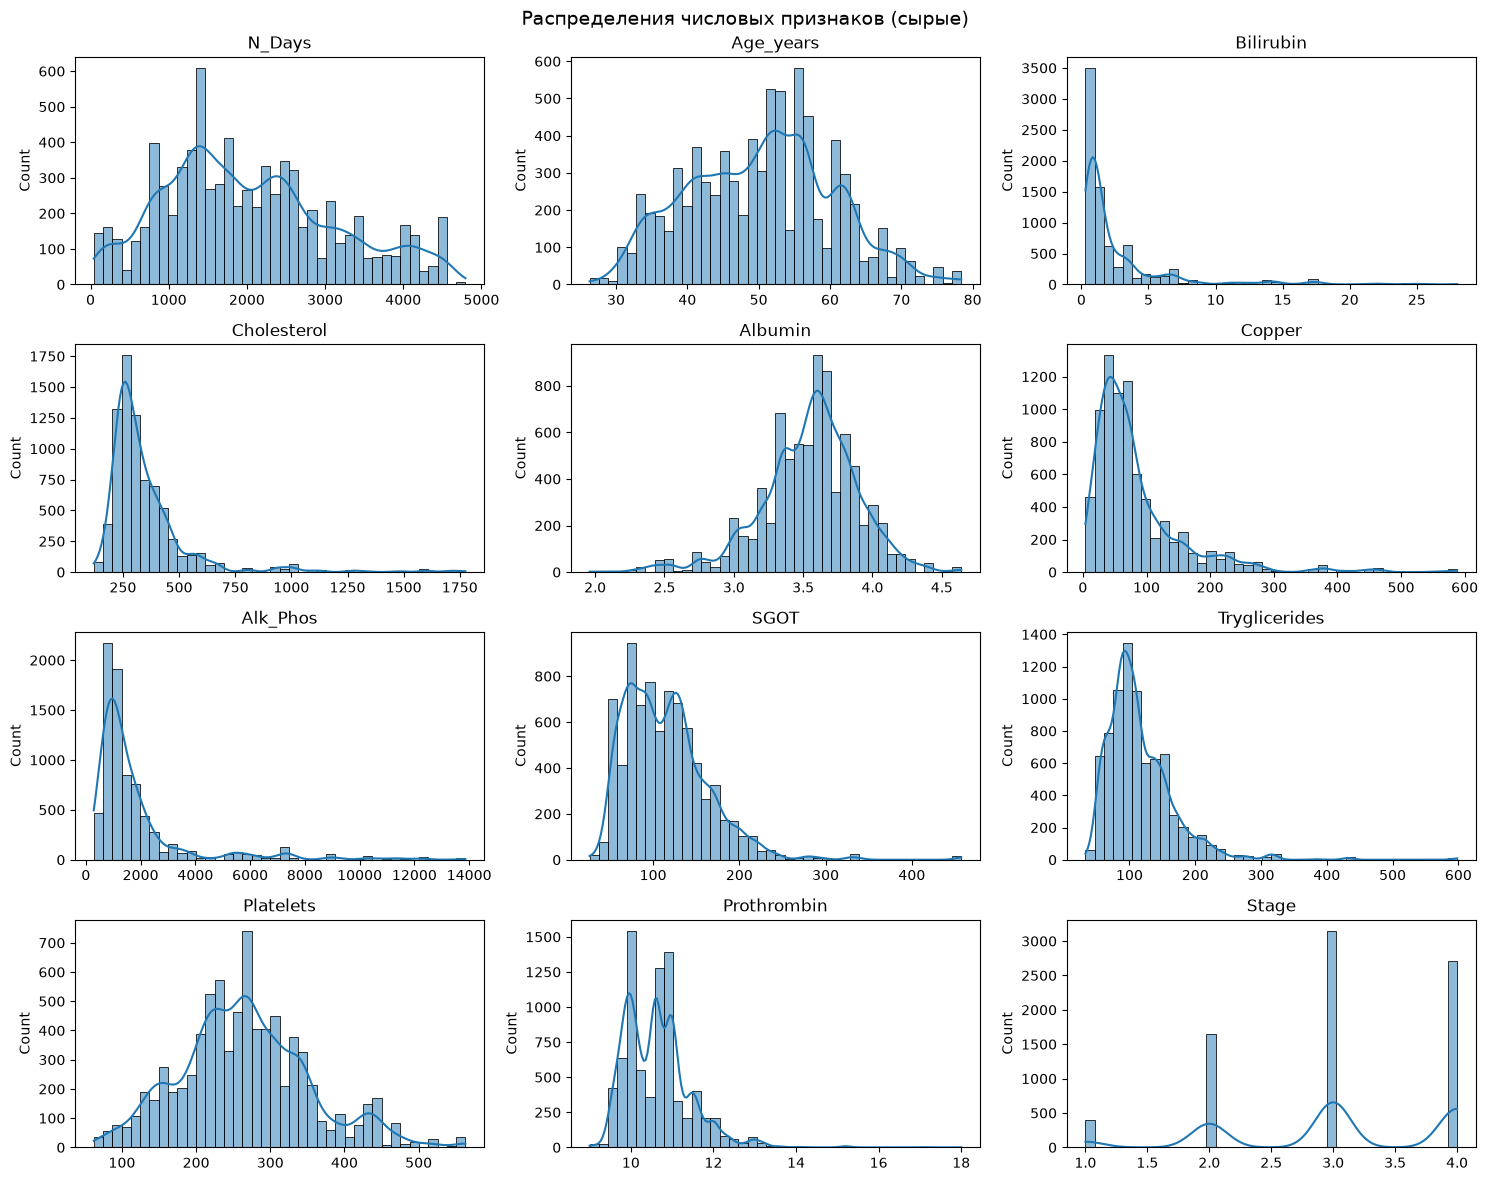

In [127]:
num_cols_now = ['N_Days','Age_years','Bilirubin','Cholesterol','Albumin','Copper',
                'Alk_Phos','SGOT','Tryglicerides','Platelets','Prothrombin','Stage']

fig, axes = plt.subplots(4, 3, figsize=(15, 12))
for ax, c in zip(axes.ravel(), num_cols_now):
    sns.histplot(df_train[c], bins=40, kde=True, ax=ax)
    ax.set_title(c)
    ax.set_xlabel('')
plt.suptitle('Распределения числовых признаков (сырые)', fontsize=14)
plt.tight_layout()
plt.show()

### 4.2 Сравнение сырых и log1p-распределений

Проверяем, какие признаки после логарифмирования становятся ближе к нормальному.
`Prothrombin` не логируем, как говорилось выше, - узкий клинический диапазон 9–18 сек, лог уничтожит сигнал.

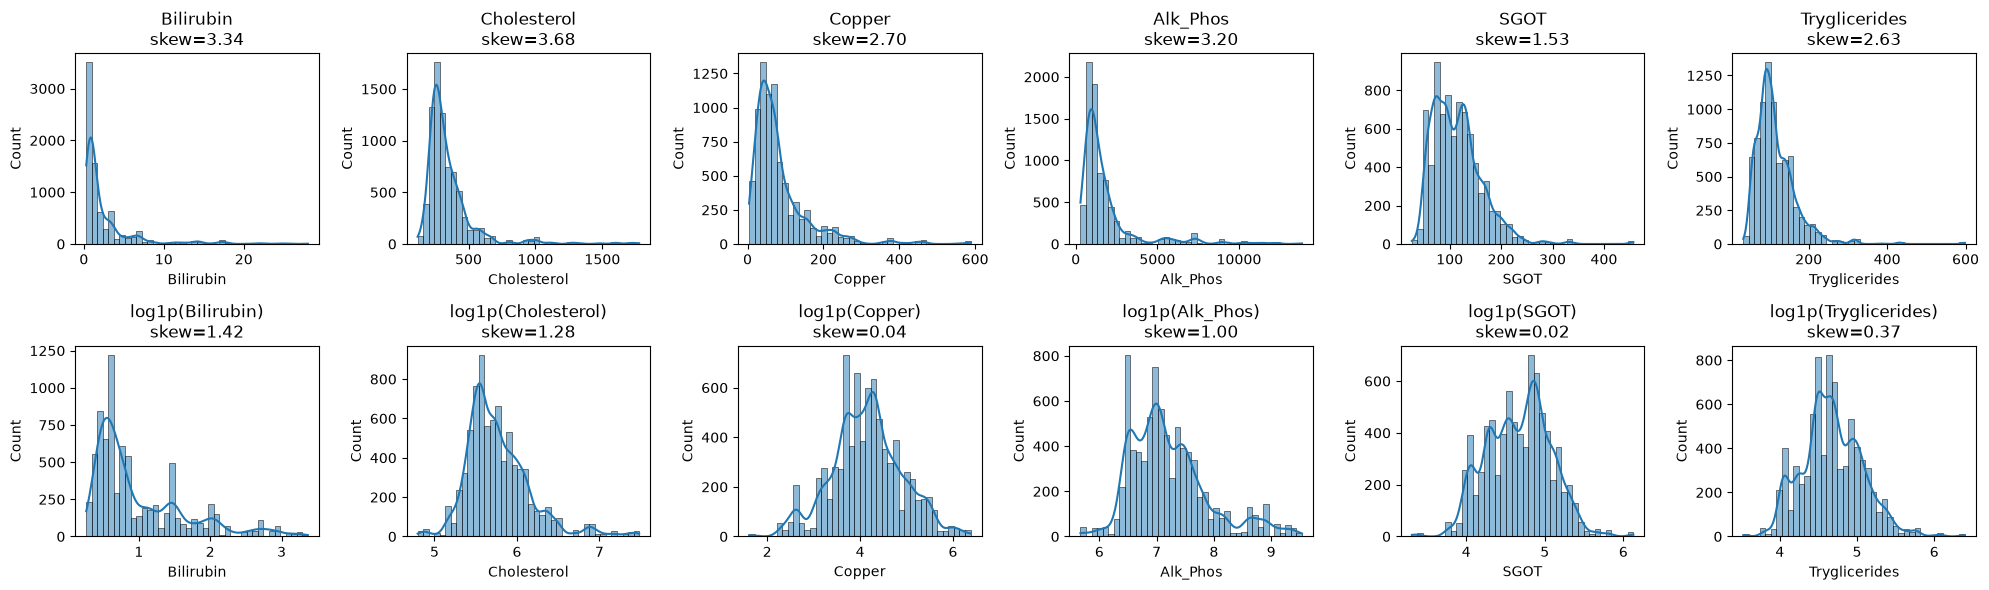

In [128]:
LOG_COLS = ['Bilirubin', 'Cholesterol', 'Copper', 'Alk_Phos', 'SGOT', 'Tryglicerides']

fig, axes = plt.subplots(2, len(LOG_COLS), figsize=(20, 6))
for i, c in enumerate(LOG_COLS):
    sns.histplot(df_train[c], bins=40, kde=True, ax=axes[0, i])
    axes[0, i].set_title(f'{c}\nskew={df_train[c].skew():.2f}')
    
    sns.histplot(np.log1p(df_train[c]), bins=40, kde=True, ax=axes[1, i])
    axes[1, i].set_title(f'log1p({c})\nskew={np.log1p(df_train[c]).skew():.2f}')
plt.tight_layout()
plt.show()

### 4.3 Подсчёт выбросов по IQR

Не удаляем, потому что в медицинских данных "выброс" = тяжёлый пациент, это сигнал.

In [129]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((s < (q1 - 1.5 * iqr)) | (s > (q3 + 1.5 * iqr))).sum())


outl = pd.Series({c: iqr_outliers(df_train[c]) for c in num_cols_now}).sort_values(
    ascending=False
)
outl.to_frame(name="n_outliers").assign(
    pct=lambda x: (x["n_outliers"] / len(df_train) * 100).round(2)
)

,n_outliers,pct
Alk_Phos,792,10.02
Bilirubin,789,9.98
Copper,655,8.29
Cholesterol,502,6.35
Tryglicerides,267,3.38
Albumin,178,2.25
Prothrombin,173,2.19
SGOT,146,1.85
Platelets,114,1.44
Age_years,36,0.46


### 4.4 Визуализация выбросов и связь с исходом

Boxplot-сетка показывает форму выбросов. Графики по `is_dead` показывают, что высокие значения (например, билирубина) характерны для умерших пациентов, поэтому мы их не удаляем.

 Длинные "усы" вправо у Alk_Phos, Bilirubin, Cholesterol и других. Это значит, что реально данные скошены, и log1p (который мы проверили в 4.2) - правильное решение.

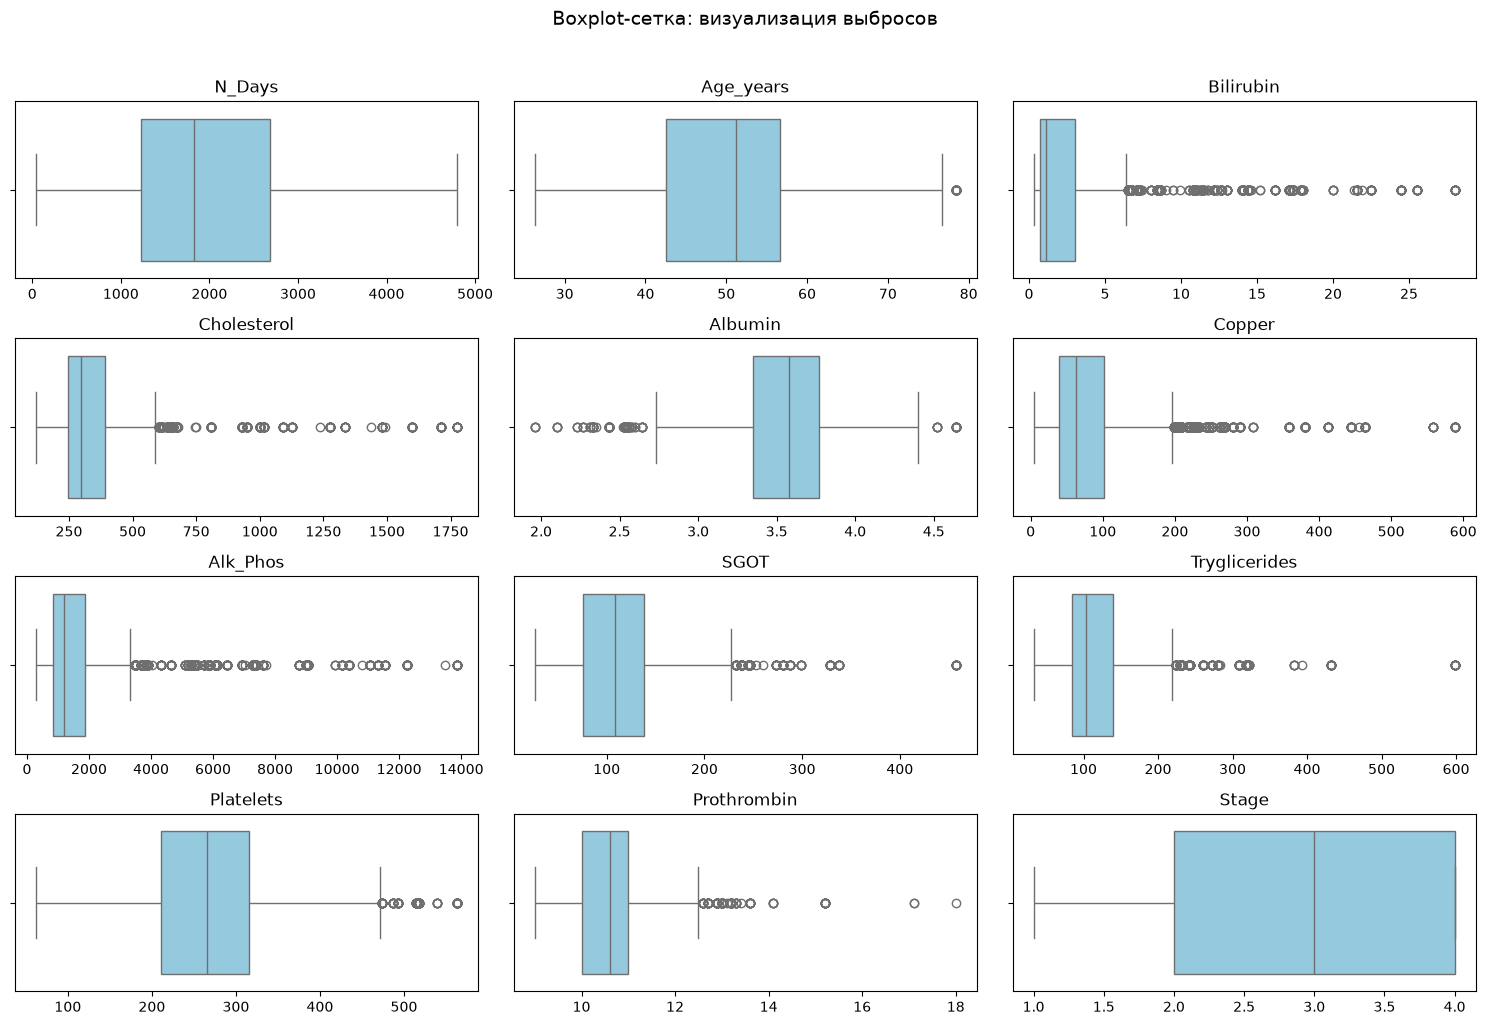

In [130]:
# Boxplot-сетка
fig, axes = plt.subplots(4, 3, figsize=(15, 10))
for ax, c in zip(axes.ravel(), num_cols_now):
    sns.boxplot(x=df_train[c], ax=ax, color='skyblue')
    ax.set_title(c)
    ax.set_xlabel('')
plt.suptitle('Boxplot-сетка: визуализация выбросов', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

C:\Users\zejna\AppData\Local\Temp\ipykernel_6596\1678408892.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_train, x='is_dead', y=c, ax=ax, palette=['#318782', '#b64d61'])
C:\Users\zejna\AppData\Local\Temp\ipykernel_6596\1678408892.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_train, x='is_dead', y=c, ax=ax, palette=['#318782', '#b64d61'])
C:\Users\zejna\AppData\Local\Temp\ipykernel_6596\1678408892.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_train, x='is_dead', y=c, ax=ax, palette=['#318782', '#b64d6

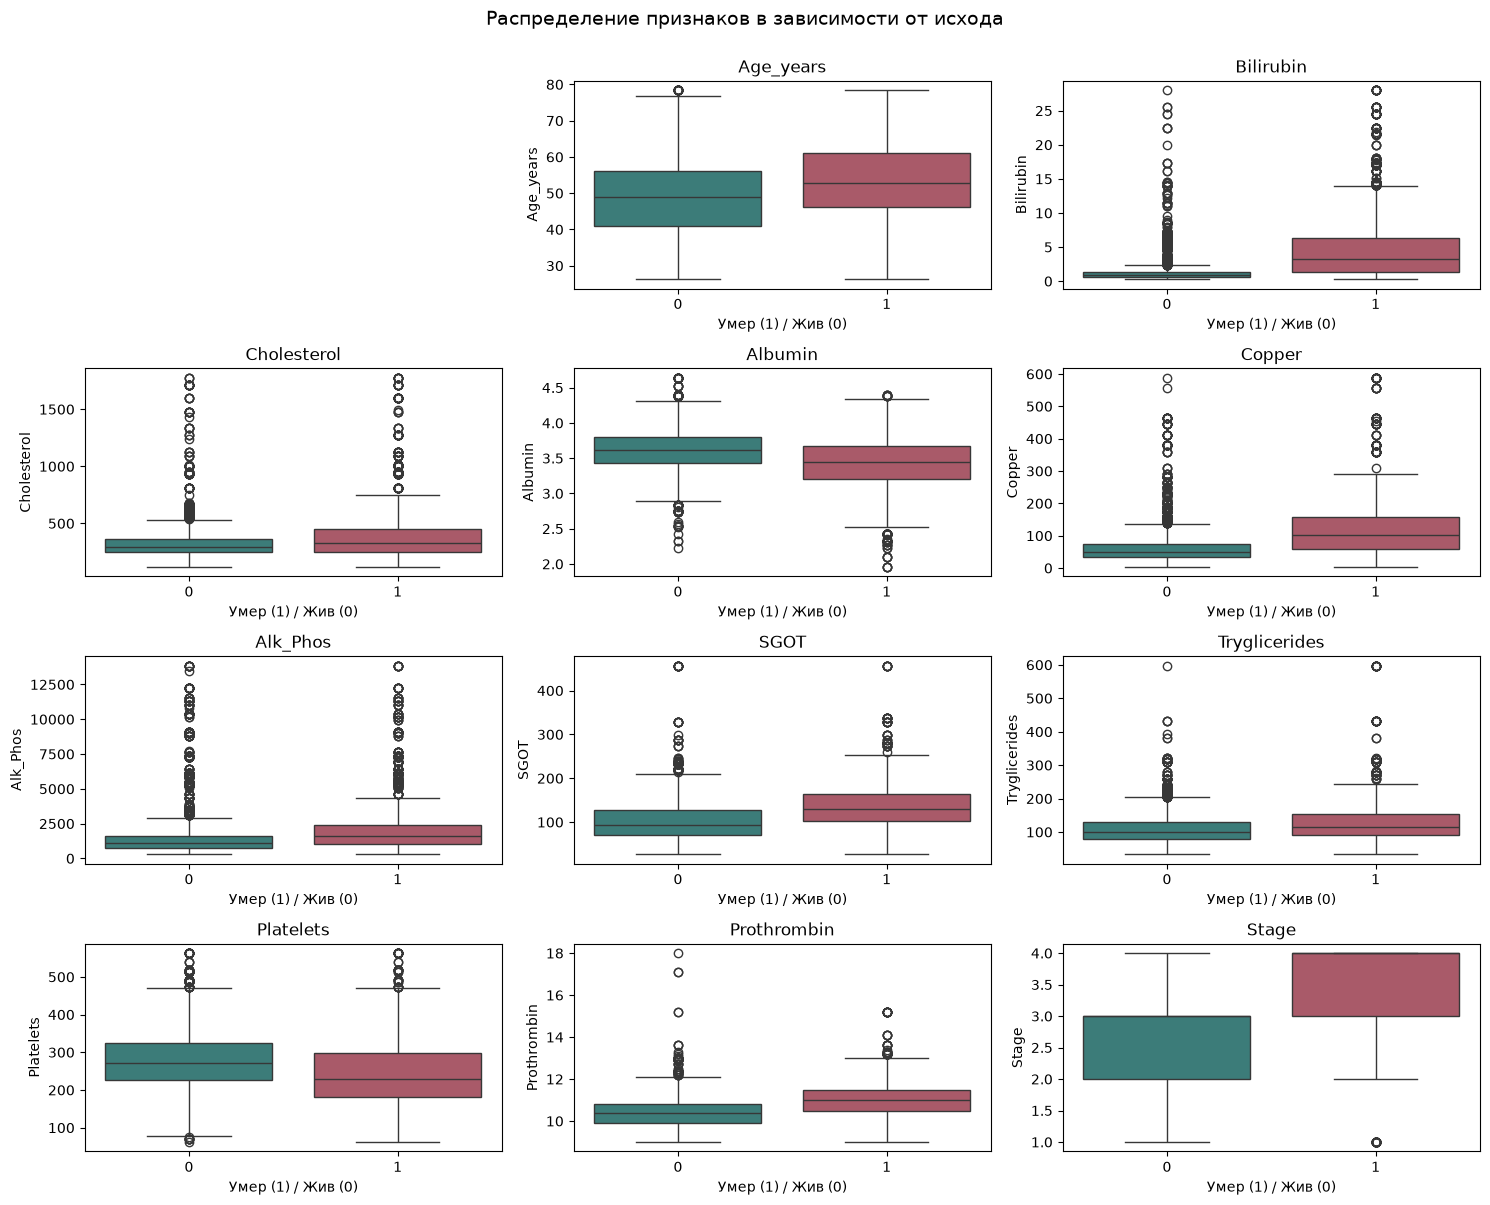

In [131]:
# Boxplot по is_dead
fig, axes = plt.subplots(4, 3, figsize=(15, 12))
for ax, c in zip(axes.ravel(), num_cols_now):
    if c == 'N_Days':
        ax.axis('off') 
        continue
    sns.boxplot(data=df_train, x='is_dead', y=c, ax=ax, palette=['#318782', '#b64d61'])
    ax.set_title(c)
    ax.set_xlabel('Умер (1) / Жив (0)')
plt.suptitle('Распределение признаков в зависимости от исхода', fontsize=14, y=1.00)
plt.tight_layout()
plt.show()

## 5. Целевая переменная

### 5.1 Распределение Status и N_Days

C:\Users\zejna\AppData\Local\Temp\ipykernel_6596\3871363630.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_train, x='Status', order=['C','CL','D'], ax=axes[0], palette=['#318782', '#dc9b2f', '#b64d61'])


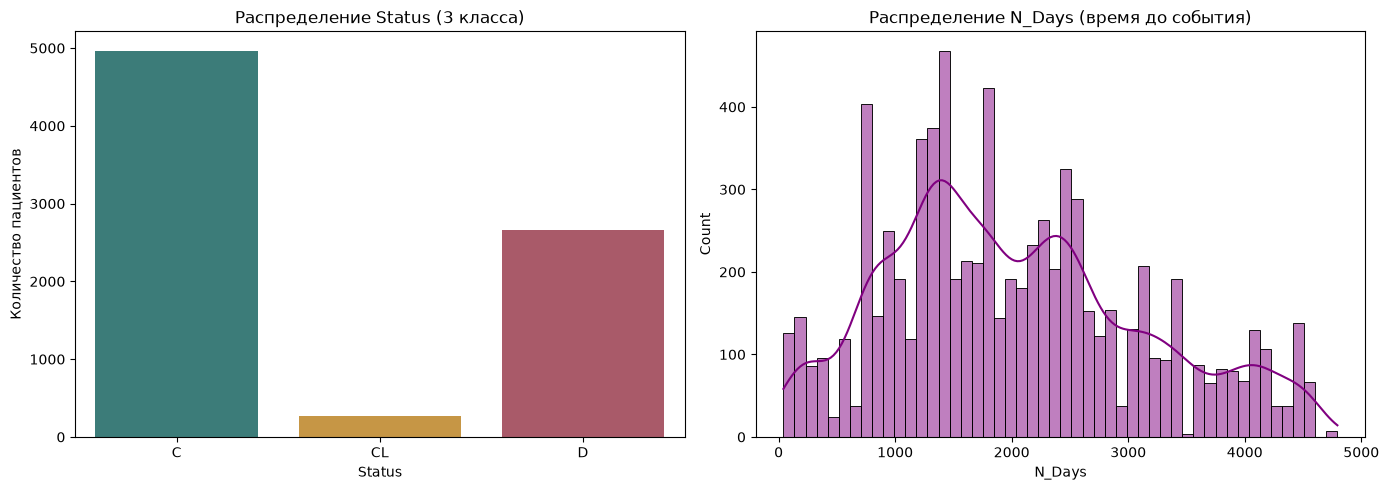

Доли классов:
Status
C     0.628
D     0.337
CL    0.035
Name: proportion, dtype: float64


In [132]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Левый график: классы Status
sns.countplot(data=df_train, x='Status', order=['C','CL','D'], ax=axes[0], palette=['#318782', '#dc9b2f', '#b64d61'])
axes[0].set_title('Распределение Status (3 класса)')
axes[0].set_ylabel('Количество пациентов')

# Правый график: распределение N_Days
sns.histplot(df_train['N_Days'], bins=50, kde=True, ax=axes[1], color='purple')
axes[1].set_title('Распределение N_Days (время до события)')

plt.tight_layout()
plt.show()

print("Доли классов:")
print(df_train['Status'].value_counts(normalize=True).round(3))

### 5.2 N_Days по Status (визуализация цензурирования)

Пациенты со `Status=C` и малым `N_Days` — это цензурирование (конец исследования), 
а не «здоровые». Это ещё одна причина дропнуть `N_Days` из фичей, чтобы модель 
не подглядывала в будущее.

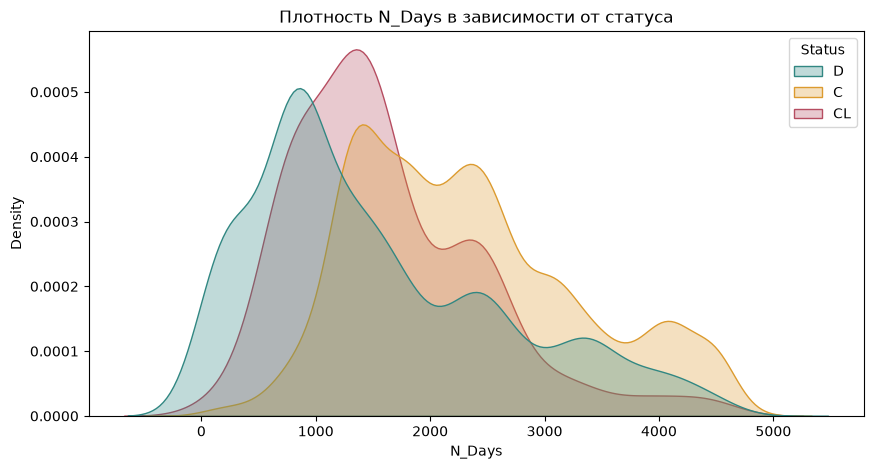

In [133]:
plt.figure(figsize=(10, 5))
sns.kdeplot(data=df_train, x='N_Days', hue='Status', common_norm=False, fill=True, alpha=0.3, palette=['#318782', '#dc9b2f', '#b64d61'])
plt.title('Плотность N_Days в зависимости от статуса')
plt.show()

## 6. Связь признаков с целевой переменной

### 6.1 Доля умерших (is_dead) по категориям

In [134]:
for c in ['Drug','Sex','Ascites','Hepatomegaly','Spiders','Edema','Stage']:
    print(df_train.groupby(c)['is_dead'].agg(['mean','count']).round(3))

       mean  count
Drug              
0     0.331   4010
1     0.344   3895
      mean  count
Sex              
0    0.320   7336
1    0.554    569
          mean  count
Ascites              
0        0.308   7525
1        0.918    380
               mean  count
Hepatomegaly              
0             0.150   3863
1             0.516   4042
          mean  count
Spiders              
0        0.252   5966
1        0.600   1939
        mean  count
Edema              
0      0.287   7161
1      0.684    399
2      0.971    345
        mean  count
Stage              
1      0.098    397
2      0.189   1652
3      0.235   3153
4      0.582   2703


### 6.2 Статистическая проверка (Хи-квадрат)

Проверяем, статистически ли значима связь категориальных признаков с исходом.
Если `p-value < 0.05`, признак значим.

In [135]:
rows = []
for c in ['Drug','Sex','Ascites','Hepatomegaly','Spiders','Edema','Stage']:
    tab = pd.crosstab(df_train[c], df_train['is_dead'])
    chi2, p, dof, _ = chi2_contingency(tab)
    rows.append({'feature': c, 'chi2': round(chi2, 2), 'p_value': p, 'significant': p < 0.05})

# Выводим таблицу, отсортированную по p-value (самые значимые сверху)
pd.DataFrame(rows).sort_values('p_value').reset_index(drop=True)

,feature,chi2,p_value,significant
0,Hepatomegaly,1180.38,1.119426e-258,True
1,Stage,1132.86,2.710054e-245,True
2,Edema,915.13,1.916678e-199,True
3,Spiders,794.75,7.480961e-175,True
4,Ascites,600.86,1.086582e-132,True
5,Sex,127.53,1.422807e-29,True
6,Drug,1.46,2.270249e-01,False


## 7. Корреляции и мультиколлинеарность


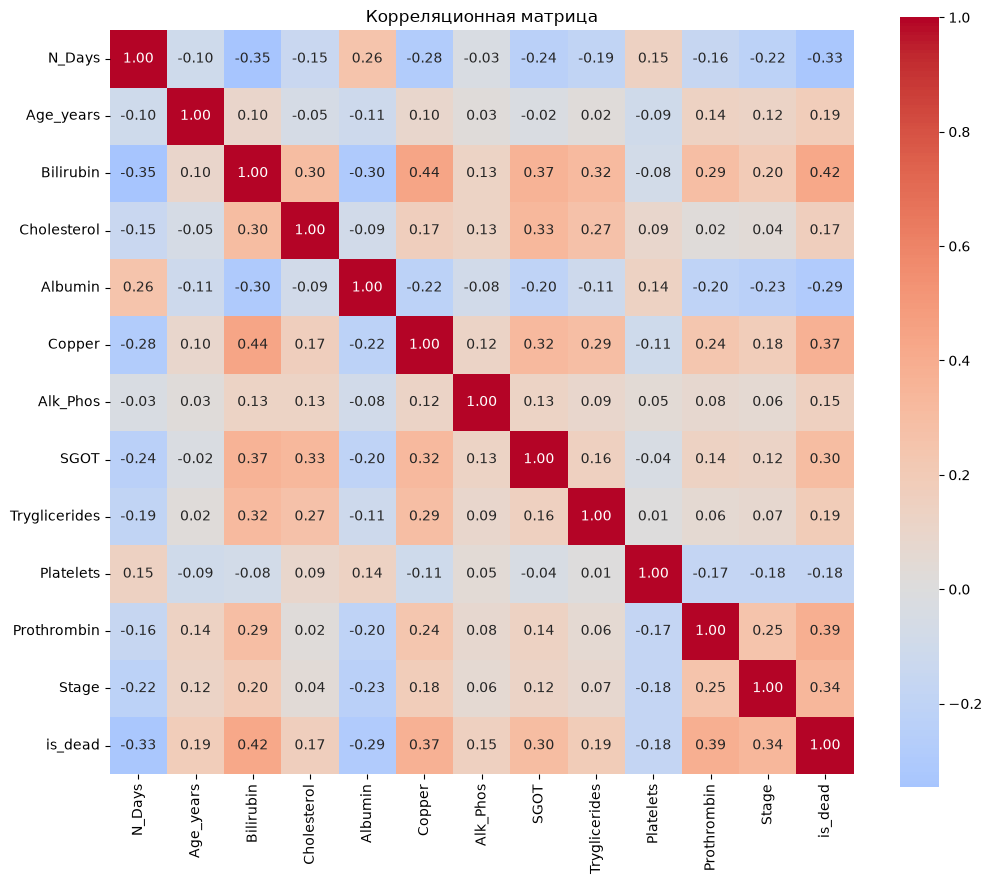


Топ признаков по |corr| с is_dead:


Bilirubin        0.423
Prothrombin      0.389
Copper           0.374
Stage            0.338
SGOT             0.301
Albumin         -0.294
Tryglicerides    0.191
Age_years        0.188
Platelets       -0.177
Cholesterol      0.173
Alk_Phos         0.153
Name: is_dead, dtype: float64

In [136]:
plt.figure(figsize=(12, 10))
corr = df_train[num_cols_now + ['is_dead']].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)
plt.title('Корреляционная матрица')
plt.show()

print("\nТоп признаков по |corr| с is_dead:")
corr['is_dead'].drop(['is_dead','N_Days']).sort_values(key=abs, ascending=False).round(3)